# Pratinjau Denah Lantai 5
Notebook ini memuat data ruangan + konfigurasi Lt. 5, memvalidasi geometri (overlap, dinding bersama, keterjangkauan) lalu menggambar denahnya. Jalankan semua sel (`Run All`) dan bandingkan dengan foto denah asli.

Kebutuhan: `pip install geopandas shapely matplotlib pandas`

In [5]:

%pip install geopandas shapely matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.1/26.1 MB 2.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 2.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [geopandas]/3 [geopandas]
Note: you may need to restart the kernel to use updated packages.


In [16]:
import io, os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from shapely.geometry import box, Point
from shapely.ops import unary_union

# --- Data ruangan (identik dengan csv/lantai5.csv) ---
CSV_TEXT = """floor,room_id,name,type,xmin,ymin,xmax,ymax
5,05003,Tangga Barat Lt 5,Stairs,0.00,50.00,2.80,60.00
5,517,Lab Histologi & PA (517),Lab,2.80,50.00,13.30,60.00
5,516,Lab Histologi & PA (516),Lab,13.30,50.00,25.60,60.00
5,515,Kelas 515,Classroom,25.60,50.00,39.70,60.00
5,518,Lab Faal & Farmakologi (518),Lab,-1.50,39.50,19.90,47.00
5,519,Kelas 519,Classroom,19.90,39.50,39.70,47.00
5,005001,Toilet Wanita Lt 5,Toilet,39.70,55.10,46.20,60.00
5,005002,Toilet Pria Lt 5,Toilet,39.70,52.20,46.20,55.10
5,005004,Toilet Disable Lt 5,Toilet,39.70,50.00,42.40,52.20
5,005003,Toilet VIP Lt 5,Toilet,42.40,50.00,46.20,52.20
5,05001,Lift Barat Lt 5,Lift,46.20,53.20,49.20,57.70
5,05002,Lift Timur Lt 5,Lift,54.30,50.00,58.00,57.70
5,05004,Tangga Utara Lt 5,Stairs,58.00,50.00,60.30,57.70
5,0005001,Pantry Lt 5,Pantry,57.50,57.70,60.30,60.00
5,507,Studio 1 (507),Classroom,60.30,50.00,74.10,60.00
5,508,Studio 2 (508),Classroom,74.10,50.00,89.20,60.00
5,509,QWERTY (509),Theater,89.20,50.00,96.10,60.00
5,05005,Tangga Timur Lt 5,Stairs,96.10,50.00,99.45,60.00
5,513,Lounge SIFT (513),Lounge,60.30,40.40,68.80,47.00
5,512,EUREKA (512),MeetingRoom,68.80,40.40,74.90,47.00
5,511,AHA (511),MeetingRoom,74.90,40.40,78.90,47.00
5,510,SIFT Colab Space (510),Lounge,78.90,39.50,99.45,47.00
5,506,DSAIRC (506),ServerRoom,39.70,35.60,50.50,46.20
5,505002,Kelas 505B,Classroom,39.70,26.00,50.50,35.60
5,505001,Kelas 505A,Classroom,39.70,16.40,50.50,26.00
5,504,Kelas 504,Classroom,39.70,1.70,50.50,16.40
5,501,Academic Support SIFT (501),Office,54.30,40.40,60.30,47.00
5,502001,Ruang Kaprodi IMT (502A),LecturerRoom,54.30,37.10,60.30,40.40
5,502002,Ruang Dekan SIFT (502B),LecturerRoom,54.30,34.00,60.30,37.10
5,502003,Ruang Kaprodi ISB (502C),LecturerRoom,54.30,30.80,60.30,34.00
5,503,Ruang Dosen SIFT (503),LecturerRoom,54.30,4.60,60.30,30.80
5,05006,Tangga Selatan Lt 5,Stairs,54.30,1.70,60.30,4.60
"""
rooms = pd.read_csv(io.StringIO(CSV_TEXT), dtype={"floor": str, "room_id": str})

# --- Konfigurasi (identik dengan floors/lantai5.py) ---
OUTLINE = [
    (-1.5, 39.5, 39.7, 47.0),
    (0.0, 47.0, 99.45, 60.0),
    (39.7, 1.7, 60.3, 47.0),
    (60.3, 40.4, 78.9, 47.0),
    (78.9, 39.5, 99.45, 47.0),
    (38.2, 1.7, 39.7, 39.5),
    (60.3, 4.6, 62.0, 40.4),
]
VOIDS = [
    (38.2, 1.7, 39.7, 39.5),
    (60.3, 4.6, 62.0, 40.4),
]
START = (51.8, 48.5)
PART_OF = {
    "513": (64.5, 47.5),
    "510": (89.0, 47.5),
}

rooms["geometry"] = [box(r.xmin, r.ymin, r.xmax, r.ymax) for r in rooms.itertuples()]
gdf = gpd.GeoDataFrame(rooms, geometry="geometry")
print(f"{len(gdf)} ruangan dimuat")
gdf[["room_id", "name", "type", "xmin", "ymin", "xmax", "ymax"]]


32 ruangan dimuat


,room_id,name,type,xmin,ymin,xmax,ymax
0,05003,Tangga Barat Lt 5,Stairs,0.0,50.0,2.80,60.0
1,517,Lab Histologi & PA (517),Lab,2.8,50.0,13.30,60.0
2,516,Lab Histologi & PA (516),Lab,13.3,50.0,25.60,60.0
3,515,Kelas 515,Classroom,25.6,50.0,39.70,60.0
4,518,Lab Faal & Farmakologi (518),Lab,-1.5,39.5,19.90,47.0
5,519,Kelas 519,Classroom,19.9,39.5,39.70,47.0
6,005001,Toilet Wanita Lt 5,Toilet,39.7,55.1,46.20,60.0
7,005002,Toilet Pria Lt 5,Toilet,39.7,52.2,46.20,55.1
8,005004,Toilet Disable Lt 5,Toilet,39.7,50.0,42.40,52.2
9,005003,Toilet VIP Lt 5,Toilet,42.4,50.0,46.20,52.2


## Validasi geometri & walkable area

In [17]:
# ===== Validasi geometri =====
overlaps, shared = [], 0
for i in range(len(gdf)):
    for j in range(i + 1, len(gdf)):
        a, b = gdf.iloc[i], gdf.iloc[j]
        inter = a.geometry.intersection(b.geometry)
        if inter.area > 1e-6:
            overlaps.append((a.room_id, b.room_id, round(inter.area, 3)))
        elif inter.length > 1e-6:
            shared += 1
print("Overlap antar ruangan :", overlaps or "tidak ada")
print("Pasangan ruangan dengan dinding bersama:", shared)

outline = unary_union([box(*b) for b in OUTLINE])
voids = unary_union([box(*b) for b in VOIDS])
outside = [r.room_id for r in gdf.itertuples() if not outline.buffer(1e-6).contains(r.geometry)]
print("Ruangan di luar OUTLINE:", outside or "tidak ada")

# ===== Walkable area (OUTLINE - ruangan - VOIDS) =====
walkable = outline.difference(unary_union(list(gdf.geometry))).difference(voids)
parts = list(walkable.geoms) if walkable.geom_type == "MultiPolygon" else [walkable]
main = next(p for p in parts if p.buffer(1e-6).contains(Point(START)))
print(f"Walkable total {walkable.area:.1f} m2 | komponen dari START {main.area:.1f} m2 | jumlah komponen {len(parts)}")

unreach = [f"{r.room_id} {r.name}" for r in gdf.itertuples() if not r.geometry.buffer(0.05).intersects(main)]
print("Ruangan yang TIDAK menyentuh area walkable:", unreach or "tidak ada")
for k, p in PART_OF.items():
    print(f"PART_OF {k} walkable?", main.buffer(1e-6).contains(Point(p)))


Overlap antar ruangan : tidak ada
Pasangan ruangan dengan dinding bersama: 34
Ruangan di luar OUTLINE: tidak ada
Walkable total 554.0 m2 | komponen dari START 554.0 m2 | jumlah komponen 1
Ruangan yang TIDAK menyentuh area walkable: tidak ada
PART_OF 513 walkable? True
PART_OF 510 walkable? True


## Gambar denah

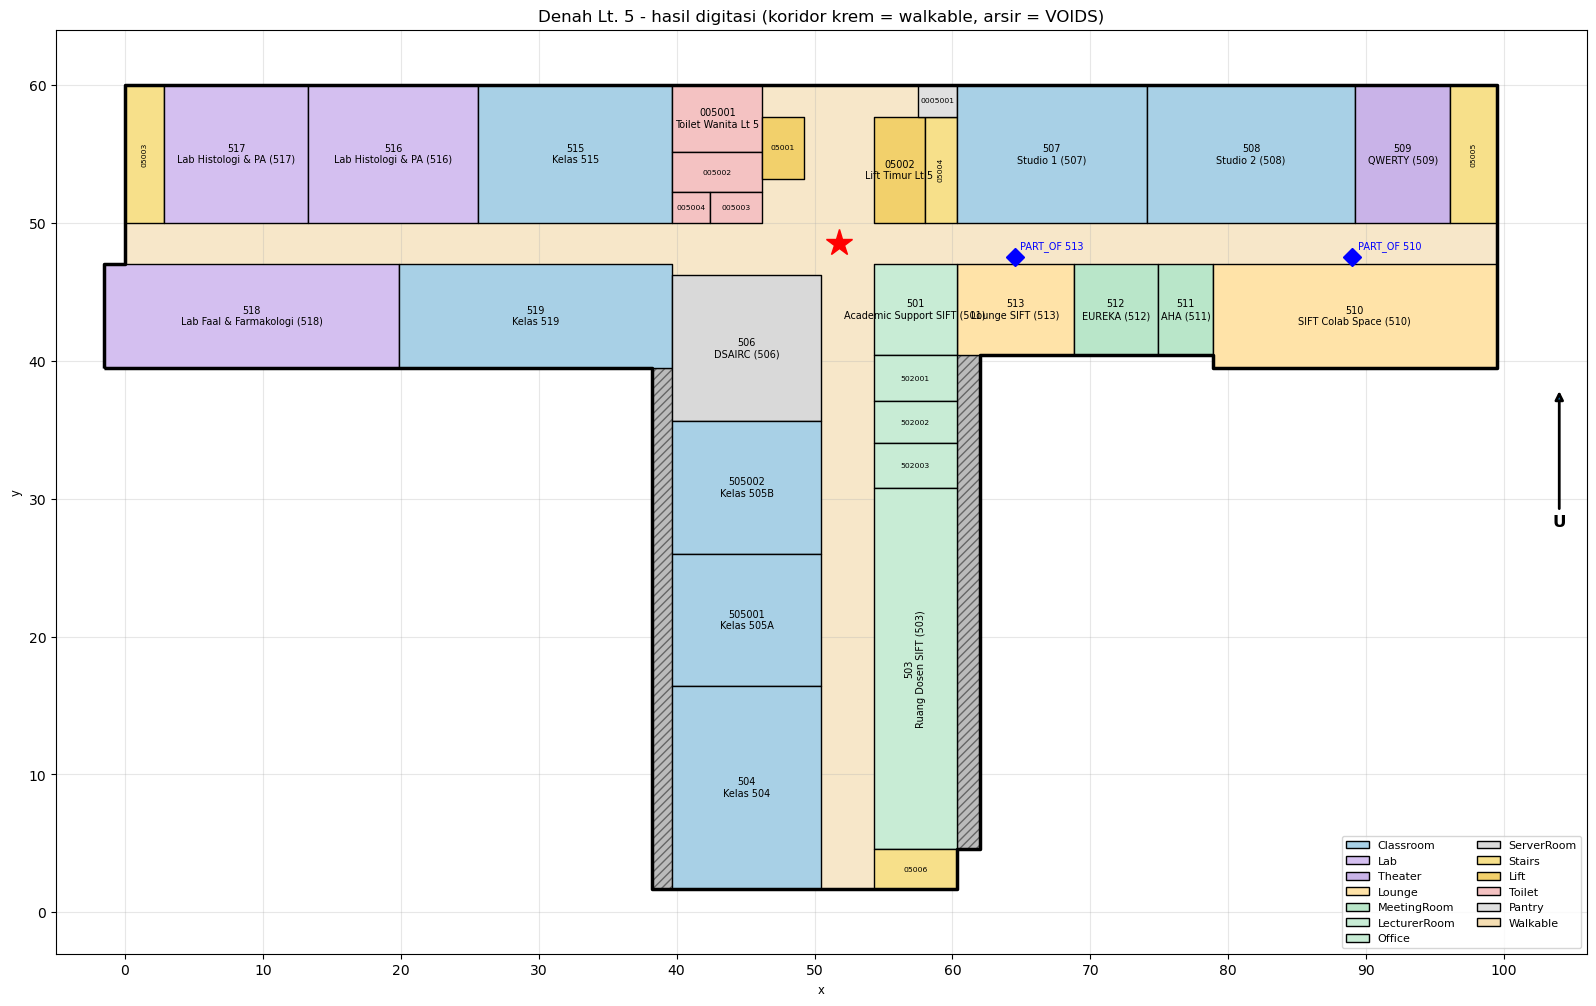

In [18]:
COLORS = {
    "Classroom": "#a8d0e6", "Lab": "#d4bff0", "Theater": "#c9b3e8", "Lounge": "#ffe3a8",
    "MeetingRoom": "#b9e6c9", "LecturerRoom": "#c8ecd5", "Office": "#c8ecd5",
    "ServerRoom": "#d9d9d9", "Stairs": "#f7e08a", "Lift": "#f2d06b",
    "Toilet": "#f4c2c2", "Pantry": "#e0e0e0",
}
fig, ax = plt.subplots(figsize=(20, 12))
gpd.GeoSeries([walkable]).plot(ax=ax, color="#f5deb3", alpha=0.7, zorder=1)
gpd.GeoSeries([voids]).plot(ax=ax, facecolor="#bbbbbb", edgecolor="#666666", hatch="////", zorder=2)
gdf.plot(ax=ax, color=gdf["type"].map(COLORS), edgecolor="black", linewidth=1.0, zorder=3)
gpd.GeoSeries([outline]).boundary.plot(ax=ax, color="black", linewidth=2.5, zorder=4)

for r in gdf.itertuples():
    cx, cy = r.geometry.centroid.x, r.geometry.centroid.y
    w, h = r.xmax - r.xmin, r.ymax - r.ymin
    small = min(w, h) < 3.6
    label = r.room_id if small else f"{r.room_id}\n{r.name}"
    ax.text(cx, cy, label, ha="center", va="center", fontsize=5.5 if small else 7,
            rotation=90 if h > 2.5 * w else 0, zorder=6)

ax.plot(*START, marker="*", color="red", markersize=20, zorder=7, label="START")
for k, p in PART_OF.items():
    ax.plot(*p, marker="D", color="blue", markersize=9, zorder=7)
    ax.annotate(f"PART_OF {k}", p, xytext=(4, 6), textcoords="offset points", fontsize=7, color="blue")

ax.annotate("U", xy=(104, 38), xytext=(104, 28), ha="center", fontsize=12, fontweight="bold",
            arrowprops=dict(arrowstyle="-|>", lw=2))
ax.set_xlim(-5, 106); ax.set_ylim(-3, 64)
ax.set_aspect("equal"); ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 101, 10)); ax.set_yticks(range(0, 61, 10))
ax.set_title("Denah Lt. 5 - hasil digitasi (koridor krem = walkable, arsir = VOIDS)")
legend = [Patch(facecolor=c, edgecolor="black", label=t) for t, c in COLORS.items()]
legend.append(Patch(facecolor="#f5deb3", edgecolor="black", label="Walkable"))
ax.legend(handles=legend, loc="lower right", fontsize=8, ncol=2)
fig.savefig("lantai5_preview.png", dpi=130, bbox_inches="tight")
plt.show()


In [19]:
rooms.to_csv("csv/lantai5.csv", index=False)

## Overlay ke foto denah asli (opsional)

In [9]:
# Opsional: tempel kerangka hasil digitasi di atas foto denah asli untuk cek kesesuaian.
# Simpan foto denah Lt. 5 sebagai "denah_lt5.jpg" di folder yang sama dengan notebook ini.
IMAGE_PATH = "denah_lt5.jpg"
if os.path.exists(IMAGE_PATH):
    import matplotlib.image as mpimg
    img = mpimg.imread(IMAGE_PATH)
    # asumsi foto 1600x1279 px; skala 15.05 px/m, origin x=70px, y=188px (y=60 m)
    extent = [-70 / 15.05, (1600 - 70) / 15.05, 60 - (1279 - 188) / 15.05, 60 + 188 / 15.05]
    fig, ax = plt.subplots(figsize=(20, 12))
    ax.imshow(img, extent=extent, zorder=0)
    gdf.boundary.plot(ax=ax, color="red", linewidth=1.3, zorder=3)
    for r in gdf.itertuples():
        ax.text(r.geometry.centroid.x, r.geometry.centroid.y, r.room_id, color="red",
                fontsize=6, ha="center", va="center", zorder=4)
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_title("Overlay: garis merah = hasil digitasi, latar = foto denah asli")
    plt.show()
else:
    print(f"{IMAGE_PATH} tidak ditemukan - lewati overlay (opsional).")


denah_lt5.jpg tidak ditemukan - lewati overlay (opsional).
